In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import pandas as pd
from torch.utils.data import Dataset
import torch.nn.init as init
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
import os
import random
from PIL import Image
from torchvision import models, transforms, utils
import re
from torchvision.transforms import v2

In [7]:
####CREACION DATASET

import os
import pandas as pd

# Directorio que contiene los archivos
directorio = './IMGS_MEDIA'

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mean = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_mean)

                            Ruta  Etiqueta
0   ./IMGS_MEDIA\_P02_HVN_1_.jpg         1
1   ./IMGS_MEDIA\_P08_HVN_1_.jpg         1
2   ./IMGS_MEDIA\_P10_HVN_1_.jpg         1
3   ./IMGS_MEDIA\_P12_HVN_0_.jpg         0
4   ./IMGS_MEDIA\_P15_HVN_0_.jpg         0
5   ./IMGS_MEDIA\_P17_HVN_0_.jpg         0
6   ./IMGS_MEDIA\_P19_HVN_0_.jpg         0
7   ./IMGS_MEDIA\_P20_HVN_0_.jpg         0
8   ./IMGS_MEDIA\_P21_HVN_1_.jpg         1
9   ./IMGS_MEDIA\_P22_HVN_1_.jpg         1
10  ./IMGS_MEDIA\_P24_HVN_1_.jpg         1
11  ./IMGS_MEDIA\_P25_HVN_0_.jpg         0
12  ./IMGS_MEDIA\_P26_HVN_0_.jpg         0
13  ./IMGS_MEDIA\_P27_HVN_1_.jpg         1
14  ./IMGS_MEDIA\_P34_HVN_0_.jpg         0
15  ./IMGS_MEDIA\_P47_HVN_0_.jpg         0
16  ./IMGS_MEDIA\_P48_HVN_0_.jpg         0
17  ./IMGS_MEDIA\_P50_H9O_1_.jpg         1
18  ./IMGS_MEDIA\_P51_H9O_0_.jpg         0
19  ./IMGS_MEDIA\_P52_H9O_1_.jpg         1
20  ./IMGS_MEDIA\_P53_H9O_0_.jpg         0
21  ./IMGS_MEDIA\_P54_H9O_1_.jpg         1
22  ./IMGS_

In [8]:
import pandas as pd
from PIL import Image
from torchvision.transforms import transforms
import os
import shutil

# Definir las transformaciones que quieres aplicar a cada imagen
data_transforms = transforms.Compose([
    # transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(1),
    transforms.RandomVerticalFlip(1),
    transforms.RandomRotation(90),
    transforms.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.5, hue=0.5),
    transforms.RandomAffine(degrees=30, translate=(0.1, 0.1), scale=(0.8, 1.2)),
    # transforms.RandomPerspective(distortion_scale=0.5, p=0.5),
    # transforms.RandomGrayscale(p=1),
])

# Función para aplicar las transformaciones a una imagen
def apply_transforms(image_path):
    image = Image.open(image_path)
    transformed_images = [t(image) for t in data_transforms.transforms] 
    return transformed_images

# Función para guardar una imagen en una carpeta
def save_image(image_tensor, original_path, destination_folder, suffix=""):
    filename = os.path.basename(original_path)
    name, ext = os.path.splitext(filename)
    for i, image in enumerate(image_tensor):
        new_filename = f"{name}{suffix}_t{i+1}{ext}"  # Agregar sufijo diferente para cada transformación
        destination_path = os.path.join(destination_folder, new_filename)
        image.save(destination_path)

# DataFrame con rutas de imágenes y etiquetas
# Supongamos que el DataFrame se llama df y tiene dos columnas: 'ruta' y 'etiqueta'
# df = pd.read_csv('tu_archivo.csv')

destination_folder = 'nueva_carpeta'
if os.path.exists(destination_folder):
    shutil.rmtree(destination_folder)
os.makedirs(destination_folder)

# Iterar sobre cada fila del DataFrame
for index, row in df_mean.iterrows():  # Asumiendo que df es tu DataFrame
    image_path = row['Ruta']
    label = row['Etiqueta']

    # Aplicar transformaciones a la imagen
    transformed_images = apply_transforms(image_path)

    # Guardar imagen transformada con sufijo
    save_image(transformed_images, image_path, destination_folder, suffix="_transformed")

# También puedes copiar las imágenes originales si lo necesitas
for index, row in df_mean.iterrows():
    image_path = row['Ruta']
    shutil.copy(image_path, destination_folder)


In [9]:
####CREACION DATASET

import os
import pandas as pd

# Directorio que contiene los archivos
directorio = './nueva_carpeta'

# Obtener la lista de archivos en el directorio
archivos = os.listdir(directorio)

# Crear una lista para almacenar las rutas de los archivos y las etiquetas
data = []

# Iterar sobre los archivos
for archivo in archivos:
    # Obtener la ruta completa del archivo
    ruta_completa = os.path.join(directorio, archivo)
    # Obtener los elementos después de hacer split("_")
    elementos = archivo.split("_")
    # Obtener la etiqueta (cuarto elemento)
    etiqueta = elementos[3] if len(elementos) >= 4 else None
    # Agregar la ruta y la etiqueta a la lista de datos
    data.append((ruta_completa, int(etiqueta)))

# Crear el DataFrame de Pandas
df_mean_aug = pd.DataFrame(data, columns=['Ruta', 'Etiqueta'])

# Mostrar el DataFrame
print(df_mean_aug)

                                               Ruta  Etiqueta
0                   ./nueva_carpeta\_P02_HVN_1_.jpg         1
1    ./nueva_carpeta\_P02_HVN_1__transformed_t1.jpg         1
2    ./nueva_carpeta\_P02_HVN_1__transformed_t2.jpg         1
3    ./nueva_carpeta\_P02_HVN_1__transformed_t3.jpg         1
4    ./nueva_carpeta\_P02_HVN_1__transformed_t4.jpg         1
..                                              ...       ...
259  ./nueva_carpeta\_P75_H9O_0__transformed_t1.jpg         0
260  ./nueva_carpeta\_P75_H9O_0__transformed_t2.jpg         0
261  ./nueva_carpeta\_P75_H9O_0__transformed_t3.jpg         0
262  ./nueva_carpeta\_P75_H9O_0__transformed_t4.jpg         0
263  ./nueva_carpeta\_P75_H9O_0__transformed_t5.jpg         0

[264 rows x 2 columns]


In [11]:
def learning_curve(train_loss, val_loss):
    epochs = range(1, len(train_loss) + 1)

    plt.plot(epochs, np.array(train_loss), label='Training Loss')
    plt.plot(epochs, np.array(val_loss), label='Validation Loss')

    plt.title('Learning Curve')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.ylim(0, 1)
    plt.legend()
    plt.show()

In [12]:
# Verificar si CUDA está disponible
cuda_available = torch.cuda.is_available()

# Imprimir la versión de PyTorch y la disponibilidad de CUDA
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {cuda_available}")

# Imprimir el nombre de la GPU si CUDA está disponible
if cuda_available:
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
    # Obtener la versión de CUDA
    cuda_version = torch.version.cuda
    print(f"CUDA version: {cuda_version}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PyTorch version: 2.2.0
CUDA available: True
GPU name: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA version: 12.1
Using device: cuda


In [14]:
def accuracy(outputs, labels):
    preds = outputs > 0.5  # Si la salida es mayor que 0.5, consideramos que es positiva
    correct = (preds == labels.byte())  # Compara las predicciones con las etiquetas reales
    acc = correct.float().sum() / labels.size(0)  # Calcula la precisión
    return acc.item()

def recall(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()
    TP = sum((preds == 1) & (labels == 1))
    FN = sum((preds == 0) & (labels == 1))
    
    recall_score = TP / (TP + FN) if (TP + FN) > 0 else 0
    return recall_score

def precision(outputs, labels):
    preds = outputs > 0.5

    preds = preds.cpu()
    labels = labels.cpu()

    TP = sum((preds == 1) & (labels == 1))
    FP = sum((preds == 1) & (labels == 0))
    
    precision_score = TP / (TP + FP) if (TP + FP) > 0 else 0
    return precision_score



def prueba_resnet_pre(dataset, num_epochs_freeze, num_epochs_all, op, batch_size, lr, data_aug, ini):
    # Transformaciones para preprocesar las imágenes
    if data_aug:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            # v2.RandomResizedCrop(224),
            # v2.RandomHorizontalFlip(),
            # v2.RandomVerticalFlip(),
            # v2.ElasticTransform(alpha=250.0),
            # v2.RandomRotation(45),
            # transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    else:
        transform_t = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

        transform_v = v2.Compose([
            v2.Resize((224, 224)),
            v2.ToImage(), 
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])
    
    # Modelo personalizado basado en ResNet
    class CustomResNet(nn.Module):
        def __init__(self, num_classes_binary=1):
            super(CustomResNet, self).__init__()
            resnet = models.resnet18(weights='IMAGENET1K_V1')
            # Extraer las capas de la red ResNet, excluyendo la capa de clasificación
            self.features = nn.Sequential(*list(resnet.children())[:-1])

            # Congelar capas preentrenadas
            for param in self.features.parameters():
                param.requires_grad = False

            # Personalizar la capa de salida para tus necesidades
            self.fc_binary = nn.Linear(512, num_classes_binary)
            
            if (ini== "G"):
                # Inicialización de Glorot para las capas fully connected
                self.apply(self.init_weights_glorot)
            elif(ini == "H"):
                self.apply(self.init_weights_he)

        def init_weights_glorot(self, m):
            if isinstance(m, nn.Linear):
                init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    init.constant_(m.bias, 0)

        def init_weights_he(self, m):
            if isinstance(m, nn.Linear):
                init.kaiming_uniform_(m.weight, mode='fan_in', nonlinearity='relu')
                if m.bias is not None:
                    init.constant_(m.bias, 0)
    
        def forward(self, x):
            x = self.features(x)
            x = x.view(x.size(0), -1)
    
    
            # Salida para la variable binaria
            out_binary = self.fc_binary(x)
    
            return out_binary
    
    # Definir una clase para el conjunto de datos personalizado
    ##adaptar esto para meter unas rutsa y obtener dataos y etiquetas
    class CustomDataset(Dataset):
        def __init__(self, dataframe, transform=None):
            self.data = dataframe
            self.transform = transform
    
        def __len__(self):
            return len(self.data)
    
        def __getitem__(self, idx):
            img_path = self.data.iloc[idx, 0]  # Ruta de la imagen en la primera columna
            image = Image.open(img_path).convert('RGB')
            # Etiquetas: una variable binaria
            label_binary = torch.tensor(self.data.iloc[idx, 1], dtype=torch.float32)
    
            if self.transform:
                image = self.transform(image)
    
            return image, label_binary
    
    
    # Definir el número de folds
    criterion_binary = nn.BCEWithLogitsLoss()
    
    train_data, val_data = train_test_split(dataset, test_size=0.2, random_state=42)
        # Crear instancias del conjunto de datos personalizado para este fold
    train_dataset = CustomDataset(dataframe=train_data, transform=transform_t)
    val_dataset = CustomDataset(dataframe=val_data, transform=transform_v)
    
    # Crear DataLoader para cargar los datos en lotes
    train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False) 
    
    model = CustomResNet(num_classes_binary=1).to(device)
    optimizer = op(model.parameters(), lr = lr)
    # Entrenamiento y validación para este fold
    train_losses = []
    val_losses = []
   

    for epoch in range(num_epochs_freeze):
        # Entrenamiento del modelo
        # Fase de entrenamiento
        model.train()
        loss_total_acumulada = 0.0
        lossT_bin_total = 0.0
        correct_train = 0
        recall_value_train = 0
        precision_value_train = 0
        for images, bin_label in train_loader:
            # for i in images:
            #     print(i.shape)
            # images_grid = utils.make_grid(images, nrow=8)  # Hacer una cuadrícula de imágenes
            # plt.figure(figsize=(10, 10))
            # plt.imshow(np.transpose(images_grid, (1, 2, 0)))  # Transponer las dimensiones para mostrar correctamente
            # plt.axis('off')
            # plt.show()
            # break  # Salir después de mostrar el primer lote
            # Reiniciar gradientes
            images, bin_label = images.to(device), bin_label.to(device)
            
            optimizer.zero_grad()
    
            # Forward pass
            bin_out = model(images)
    
            # Calcular pérdida para las variables continuas
            
    
    
            # Calcular pérdida para la variable binaria
            lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
            # Pérdida total
            loss_total = lossT_bin

            loss_total_acumulada += loss_total

            # Backward pass y optimización
            loss_total.backward()
            optimizer.step()
            bin_pred = torch.sigmoid(bin_out.squeeze())
            correct_train += accuracy(bin_pred, bin_label)
            recall_value_train += recall(bin_pred, bin_label)
            precision_value_train += precision(bin_pred, bin_label)
    

        # Validación del modelo
        model.eval()
        val_loss = 0.0
        correct_valid = 0
        recall_value_valid = 0
        precision_value_valid = 0
        lossV_bin_total = 0.0
        with torch.no_grad():
            for images, bin_label in val_loader:
                images,  bin_label = images.to(device),  bin_label.to(device)
                ##print(len(images)) aqui se hace con 32 imagenes
                # Forward pass en el conjunto de validación
                bin_out = model(images)



                # Calcular pérdida para la variable binaria
                lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)

                # Sumar las pérdidas del conjunto de validación
                val_loss += lossV_bin.item()
                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_valid += accuracy(bin_pred, bin_label)
                recall_value_valid += recall(bin_pred, bin_label)
                precision_value_valid += precision(bin_pred, bin_label)
                
        
        
        avg_loss_total_acumulada = loss_total_acumulada / len(train_loader)
        train_losses.append(avg_loss_total_acumulada)
        acc_train = correct_train / len(train_loader)
        recall_train = recall_value_train / len(train_loader)
        precision_train = precision_value_train / len(train_loader)
       
        avg_val_loss = val_loss / len(val_loader)
        val_losses.append(avg_val_loss)
        acc_valid = correct_valid / len(val_loader)
        recall_valid = recall_value_valid / len(val_loader)
        precision_valid = precision_value_valid / len(val_loader)
        
        print(f'Epoch [{epoch+1}/{num_epochs_freeze+num_epochs_all}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

    ##Se descongelan todas
    for param in model.features.parameters():
        param.requires_grad = True
        
    for epoch in range(num_epochs_freeze, num_epochs_freeze + num_epochs_all):
        # Entrenamiento del modelo
        # Fase de entrenamiento
        model.train()
        loss_total_acumulada = 0.0
        lossT_bin_total = 0.0
        correct_train = 0
        recall_value_train = 0
        precision_value_train = 0
        for images, bin_label in train_loader:
            # Reiniciar gradientes
            images, bin_label = images.to(device), bin_label.to(device)
    
            optimizer.zero_grad()
    
            # Forward pass
            bin_out = model(images)
    
            # Calcular pérdida para las variables continuas
            
    
    
            # Calcular pérdida para la variable binaria
            lossT_bin = criterion_binary(bin_out.squeeze(1), bin_label)
    
            # Pérdida total
            loss_total = lossT_bin

            loss_total_acumulada += loss_total

            # Backward pass y optimización
            loss_total.backward()
            optimizer.step()
            bin_pred = torch.sigmoid(bin_out.squeeze())
            correct_train += accuracy(bin_pred, bin_label)
            recall_value_train += recall(bin_pred, bin_label)
            precision_value_train += precision(bin_pred, bin_label)
    

        # Validación del modelo
        model.eval()
        val_loss = 0.0
        correct_valid = 0
        recall_value_valid = 0
        precision_value_valid = 0
        lossV_bin_total = 0.0
        with torch.no_grad():
            for images, bin_label in val_loader:
                images,  bin_label = images.to(device),  bin_label.to(device)
                ##print(len(images)) aqui se hace con 32 imagenes
                # Forward pass en el conjunto de validación
                bin_out = model(images)



                # Calcular pérdida para la variable binaria
                lossV_bin = criterion_binary(bin_out.squeeze(1), bin_label)

                # Sumar las pérdidas del conjunto de validación
                val_loss += lossV_bin.item()
                bin_pred = torch.sigmoid(bin_out.squeeze())
                correct_valid += accuracy(bin_pred, bin_label)
                recall_value_valid += recall(bin_pred, bin_label)
                precision_value_valid += precision(bin_pred, bin_label)
                # print(bin_pred>0.5)
                # print(bin_label)
                # print(recall(bin_pred, bin_label))
                # print(accuracy(bin_pred, bin_label))
                
        
        
        avg_loss_total_acumulada = loss_total_acumulada / len(train_loader)
        train_losses.append(avg_loss_total_acumulada)
        acc_train = correct_train / len(train_loader)
        recall_train = recall_value_train / len(train_loader)
        precision_train = precision_value_train / len(train_loader)
       
    
        avg_val_loss = val_loss / len(val_loader)
        val_losses.append(avg_val_loss)
        acc_valid = correct_valid / len(val_loader)
        recall_valid = recall_value_valid / len(val_loader)
        precision_valid = precision_value_valid / len(val_loader)
        
        print(f'Epoch [{epoch+1}/{num_epochs_freeze+num_epochs_all}], Training Loss: {avg_loss_total_acumulada.item()}, Validation Loss: {avg_val_loss}')

    
    train_losses = [i.cpu().detach().numpy() for i in train_losses]
    learning_curve(train_losses, val_losses)
    
        

Epoch [1/33], Training Loss: 0.6932343244552612, Validation Loss: 0.7338055074214935
Epoch [2/33], Training Loss: 0.6773826479911804, Validation Loss: 0.7219270169734955
Epoch [3/33], Training Loss: 0.6723262667655945, Validation Loss: 0.6905572414398193
Epoch [4/33], Training Loss: 0.725892186164856, Validation Loss: 0.5235660374164581
Epoch [5/33], Training Loss: 0.2948155999183655, Validation Loss: 0.5002307295799255
Epoch [6/33], Training Loss: 0.19383102655410767, Validation Loss: 0.749955415725708
Epoch [7/33], Training Loss: 0.08381140977144241, Validation Loss: 0.4458288550376892
Epoch [8/33], Training Loss: 0.15231697261333466, Validation Loss: 0.7515796720981598
Epoch [9/33], Training Loss: 0.13715019822120667, Validation Loss: 0.6695654690265656
Epoch [10/33], Training Loss: 0.048642467707395554, Validation Loss: 0.3830462247133255
Epoch [11/33], Training Loss: 0.027460983023047447, Validation Loss: 0.33299462497234344
Epoch [12/33], Training Loss: 0.017428454011678696, Vali

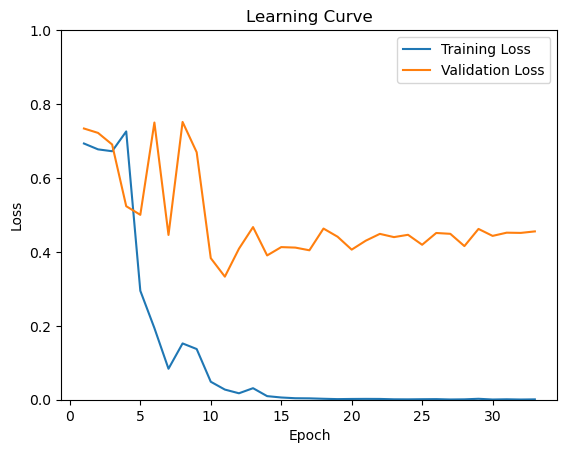

In [15]:
prueba_resnet_pre(df_mean_aug,3,30,optim.RMSprop, 32, 0.0001, True, None)